Rotation Testing

In [117]:
import numpy as np
import torch
from DatasetLoading import RepairDatasetLoader
from scipy.spatial.transform import Rotation

In [118]:
random_pointcloud = torch.rand(size=(2500, 3)).float() * 10 - 5
random_normals = torch.nn.functional.normalize(torch.rand(size=(2500, 3)).float() * 10 - 5)

In [119]:
dataset_loader = RepairDatasetLoader(batch_size=4, dataset_type="RandomDualRotationPointCloudsDataloader",
                                         representation_folder_name="pointclouds2_5k", num_workers=8, data_dir="~/Documents/masters/datasets/", angle_divider=4)
test_dataloader = dataset_loader.test_dataloader()

In [15]:
identity_rotation = test_dataloader.dataset.euler_to_matrix(0,0,0)
identity_rotation

array([[1., 0., 0.],
       [0., 1., 0.],
       [0., 0., 1.]])

In [17]:
identity_rotation_as_rotation = Rotation.from_matrix(identity_rotation)
identity_rotation_as_rotation

Rotation.from_matrix(array([[1., 0., 0.],
                            [0., 1., 0.],
                            [0., 0., 1.]]))

In [65]:
random_pointcloud.shape

torch.Size([2500, 3])

In [22]:
unrotated_points, unrotated_normals = test_dataloader.dataset.rotate_pointcloud(random_pointcloud, random_normals, identity_rotation_as_rotation)

In [24]:
torch.aminmax(random_pointcloud - unrotated_points)

torch.return_types.aminmax(
min=tensor(0.),
max=tensor(0.))

In [25]:
torch.aminmax(unrotated_normals - random_normals)

torch.return_types.aminmax(
min=tensor(0.),
max=tensor(0.))

In [31]:
from copy import deepcopy
import math

In [36]:
random_rotations = [test_dataloader.dataset.get_random_angle_dcp(6) for i in range(1000)]
modified_random_pointcloud = random_pointcloud.clone()
modified_random_normals = random_normals.clone()
for i, rotation_pair in enumerate(random_rotations):
    rotation, matrix_rotation = rotation_pair
    assert matrix_rotation.shape == (3,3)
    # check determinant = 1
    assert math.isclose(np.linalg.det(matrix_rotation), 1.0)
    modified_random_pointcloud, modified_random_normals = test_dataloader.dataset.rotate_pointcloud(modified_random_pointcloud, modified_random_normals, rotation)

for i, rotation_pair in enumerate(reversed(random_rotations)):
    rotation, matrix_rotation = rotation_pair
    rotation = rotation.inv()
    modified_random_pointcloud, modified_random_normals = test_dataloader.dataset.rotate_pointcloud(modified_random_pointcloud, modified_random_normals, rotation)

print(torch.aminmax(random_pointcloud - modified_random_pointcloud))
print(torch.aminmax(modified_random_normals - random_normals))



torch.return_types.aminmax(
min=tensor(-3.5763e-05),
max=tensor(3.8147e-05))
torch.return_types.aminmax(
min=tensor(-5.3644e-06),
max=tensor(5.0664e-06))


In [48]:
rotate = lambda points, rot : (rot @ points.transpose(2, 1)).transpose(2, 1)

In [115]:
for i, batch in enumerate(test_dataloader):
    pc_info1, pc_info2, rotation_info = batch
    matrix_rotation, rotation = rotation_info
    assert matrix_rotation.shape == (4, 3, 3)


    print(torch.aminmax(rotate(pc_info1[0], matrix_rotation) - pc_info2[0]))
    print(torch.aminmax(rotate(pc_info1[1], matrix_rotation) - pc_info2[1]))
    assert torch.allclose(matrix_rotation.transpose(1, 2) @ matrix_rotation, torch.eye(3).unsqueeze(0).repeat(matrix_rotation.shape[0], 1, 1), atol=1e-5)

torch.return_types.aminmax(
min=tensor(-8.9407e-08),
max=tensor(5.9605e-08))
torch.return_types.aminmax(
min=tensor(-1.7881e-07),
max=tensor(2.3842e-07))
torch.return_types.aminmax(
min=tensor(-8.9407e-08),
max=tensor(8.9407e-08))
torch.return_types.aminmax(
min=tensor(-1.7881e-07),
max=tensor(1.7881e-07))
torch.return_types.aminmax(
min=tensor(-8.9407e-08),
max=tensor(5.9605e-08))
torch.return_types.aminmax(
min=tensor(-1.7881e-07),
max=tensor(1.7881e-07))
torch.return_types.aminmax(
min=tensor(-8.9407e-08),
max=tensor(8.9407e-08))
torch.return_types.aminmax(
min=tensor(-1.7881e-07),
max=tensor(1.7881e-07))
torch.return_types.aminmax(
min=tensor(-8.9407e-08),
max=tensor(8.9407e-08))
torch.return_types.aminmax(
min=tensor(-1.7881e-07),
max=tensor(2.3842e-07))
torch.return_types.aminmax(
min=tensor(-5.9605e-08),
max=tensor(7.4506e-08))
torch.return_types.aminmax(
min=tensor(-1.7881e-07),
max=tensor(1.7881e-07))
torch.return_types.aminmax(
min=tensor(-5.9605e-08),
max=tensor(8.9407e-08))

In [114]:
matrix_rotation[0]

tensor([[ 0.9333, -0.3542,  0.0593],
        [ 0.3572,  0.9327, -0.0504],
        [-0.0375,  0.0682,  0.9970]])

In [103]:
print(pc_info1[0] - pc_info2[0])

tensor([[[ 3.8812e-02,  4.9290e-02, -1.3180e-02],
         [-5.3893e-04,  7.9546e-02, -1.0736e-02],
         [ 7.9022e-03, -4.9983e-02,  5.4846e-03],
         ...,
         [-4.4803e-02, -2.6443e-02,  1.1069e-02],
         [ 4.0108e-02, -2.7942e-02, -2.8853e-03],
         [-9.0380e-02, -3.1222e-02,  1.9320e-02]],

        [[-3.8310e-02, -7.4178e-02,  5.8420e-02],
         [-1.0833e-02,  3.4056e-02,  2.2411e-05],
         [ 2.4537e-02,  2.8666e-02, -3.1768e-02],
         ...,
         [ 2.4588e-02,  4.7370e-02, -3.7424e-02],
         [-2.5004e-02, -3.3747e-02,  3.3733e-02],
         [-1.7917e-02,  9.9061e-02, -1.2774e-02]],

        [[ 6.7525e-02, -8.5885e-02,  3.4318e-02],
         [-2.3651e-02,  4.7343e-02, -2.7773e-02],
         [ 1.8495e-02, -3.3634e-02,  1.8626e-02],
         ...,
         [ 1.0294e-01, -2.7237e-02, -4.2315e-02],
         [-7.4302e-02, -6.1193e-03,  5.4072e-02],
         [ 5.9724e-02,  3.4930e-02, -7.0854e-02]],

        [[ 8.6239e-02, -5.8463e-02, -4.8765e-02],
  

<Axes: ylabel='Count'>

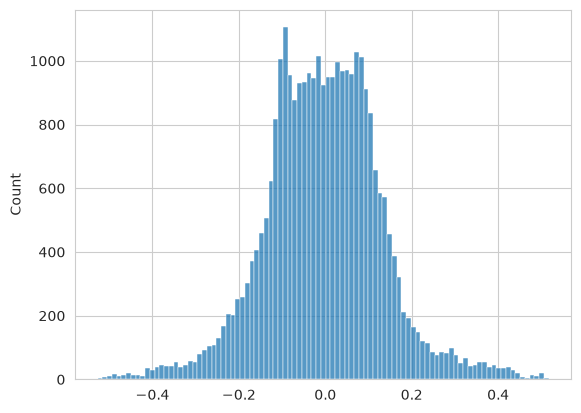

In [112]:
sns.histplot(pc_info1[0].view(-1))

In [93]:
r1 = Rotation.random()
r2, _ = test_dataloader.dataset.get_random_angle_dcp(6)
t1_pc, t1_n = test_dataloader.dataset.rotate_pointcloud(random_pointcloud.clone(), random_normals.clone(), r2 * r1)
pc1, n1 = test_dataloader.dataset.rotate_pointcloud(random_pointcloud.clone(), random_normals.clone(), r1)
t2_pc, t2_n = test_dataloader.dataset.rotate_pointcloud(pc1, n1, r2)
assert torch.allclose(t1_pc, t2_pc)
assert torch.allclose(t1_n, t2_n)

AssertionError: 

In [94]:
t1_pc

tensor([[-5.0110, -0.8912,  2.6929],
        [ 2.3652, -3.0230,  0.3293],
        [-3.4403,  3.4227, -2.4898],
        ...,
        [ 1.0252,  1.9689,  0.8410],
        [-3.8809, -1.2108, -2.4076],
        [ 2.1720, -2.3870,  2.1560]])

In [110]:
torch.aminmax(t1_pc)

torch.return_types.aminmax(
min=tensor(-6.8048),
max=tensor(7.1842))

In [105]:
import seaborn as sns

In [107]:
t1_pc[0].view(-1)

tensor([-5.0110, -0.8912,  2.6929])

<Axes: ylabel='Count'>

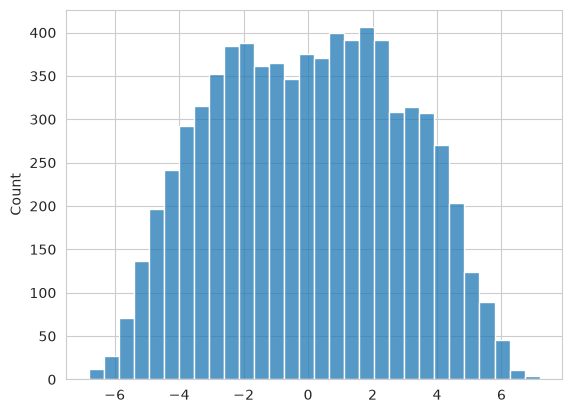

In [108]:
sns.histplot(t1_pc.view(-1).numpy())

In [95]:
t2_pc

tensor([[-5.0110, -0.8912,  2.6929],
        [ 2.3652, -3.0230,  0.3293],
        [-3.4403,  3.4227, -2.4898],
        ...,
        [ 1.0252,  1.9689,  0.8410],
        [-3.8809, -1.2108, -2.4076],
        [ 2.1720, -2.3870,  2.1560]])

In [99]:
torch.aminmax(t1_pc - t2_pc)

torch.return_types.aminmax(
min=tensor(-1.4305e-06),
max=tensor(9.5367e-07))

In [97]:
torch.allclose(t1_pc, t2_pc)

False

In [87]:
matrix_rotation[0]

tensor([[ 0.9592, -0.2640,  0.1012],
        [ 0.2812,  0.8534, -0.4389],
        [ 0.0295,  0.4495,  0.8928]])

In [90]:
Rotation.from_quat(rotation[0]).as_matrix()

array([[ 0.95920852, -0.26398361,  0.10115174],
       [ 0.28115123,  0.85340251, -0.4389284 ],
       [ 0.02954675,  0.4494628 ,  0.89281027]])

In [74]:
test_points = torch.tensor([[[1, 0, 0], [0, 1, 0], [0, 0, 1], [0,0,0]]], dtype=torch.float32)
print(test_points.shape)
test_points

torch.Size([1, 4, 3])


tensor([[[1., 0., 0.],
         [0., 1., 0.],
         [0., 0., 1.],
         [0., 0., 0.]]])

In [79]:
test_rotation = test_dataloader.dataset.euler_to_matrix(np.pi/2,0,0)
test_rotation = torch.from_numpy(test_rotation).float().unsqueeze(0)
test_rotation

tensor([[[ 1.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  6.1232e-17, -1.0000e+00],
         [ 0.0000e+00,  1.0000e+00,  6.1232e-17]]])

In [80]:
rotate(test_points, test_rotation)

tensor([[[ 1.0000e+00,  0.0000e+00,  0.0000e+00],
         [ 0.0000e+00,  6.1232e-17,  1.0000e+00],
         [ 0.0000e+00, -1.0000e+00,  6.1232e-17],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00]]])

In [85]:
test_dataloader.dataset.rotate_pointcloud(test_points[0], test_points[0], Rotation.from_matrix(test_rotation[0].numpy()))[0]

tensor([[ 1.,  0.,  0.],
        [ 0.,  0.,  1.],
        [ 0., -1.,  0.],
        [ 0.,  0.,  0.]])

In [86]:
torch.allclose(rotate(test_points, test_rotation), test_dataloader.dataset.rotate_pointcloud(test_points[0], test_points[0], Rotation.from_matrix(test_rotation[0].numpy()))[0])

True

PointCloud Embedding Testing


In [120]:
from EvaluationUtils import encoders

In [128]:
PTV3 = encoders["PTV3"]()

In [129]:
dataset_loader = RepairDatasetLoader(batch_size=4, dataset_type="RandomDualRotationPointCloudsDataloader",
                                         representation_folder_name="pointclouds2_5k", num_workers=8, data_dir="~/Documents/masters/datasets/", angle_divider=4)
test_dataloader = dataset_loader.test_dataloader()

In [130]:
def pca_color(feat: torch.Tensor) -> torch.Tensor:
    """Map a per-point feature (N, C) to RGB in [0, 1] through its top principal components."""
    _, _, components = torch.pca_lowrank(feat, center=True, q=6, niter=5)
    projected = feat @ components
    projected = projected[:, :3] * 0.6 + projected[:, 3:6] * 0.4
    low, high = projected.min(0, keepdim=True).values, projected.max(0, keepdim=True).values
    return ((projected - low) / (high - low).clamp_min(1e-6)).clamp(0, 1)




In [131]:
import matplotlib.pyplot as plt


def show_clouds(clouds, titles, point_size=1.0, columns=None, height=4.4):
    """Draw one cloud per panel, colored by its own `color`: RGB rows in [0, 1], or one color for the panel."""
    columns = columns or len(clouds)
    rows = -(-len(clouds) // columns)
    _, axes = plt.subplots(rows, columns, figsize=(4.4 * columns, height * rows), subplot_kw={"projection": "3d"})
    for ax, cloud, title in zip(np.ravel(axes), clouds, titles):
        pos = np.asarray(cloud["pos"])
        ax.scatter(*pos.T, c=cloud["color"], s=point_size, linewidths=0, depthshade=False)
        ax.set_box_aspect(np.ptp(pos, axis=0))
        ax.set_title(title, fontsize=10)
        ax.set_axis_off()
    plt.show()




In [132]:
batch = next(iter(test_dataloader))

In [135]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [140]:
pc_info1, pc_info2, rotation_info = batch
to_device = lambda x : [a.to(device) for a in x]
pc_info1 = to_device(pc_info1)
pc_info2 = to_device(pc_info2)

In [141]:
ptv3_features_pc1 = PTV3(pc_info1)
ptv3_features_pc2 = PTV3(pc_info2)

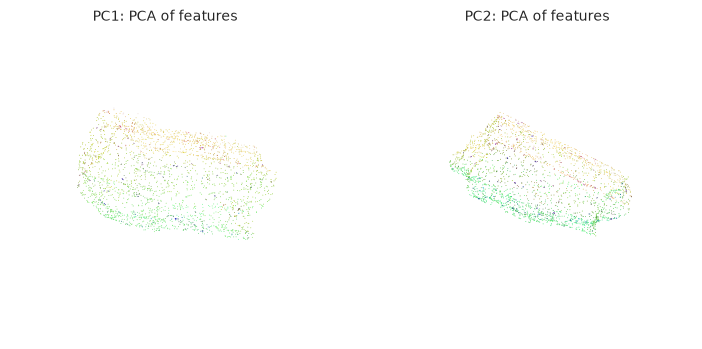

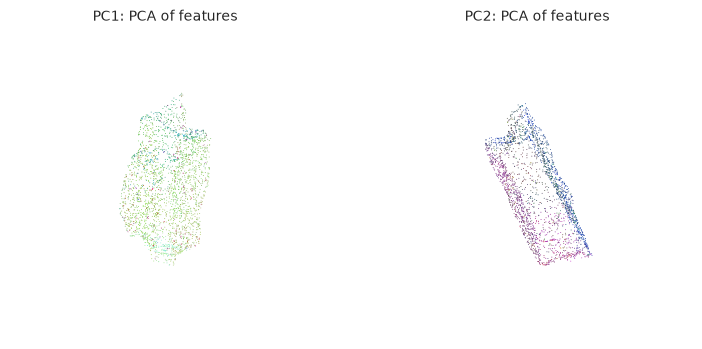

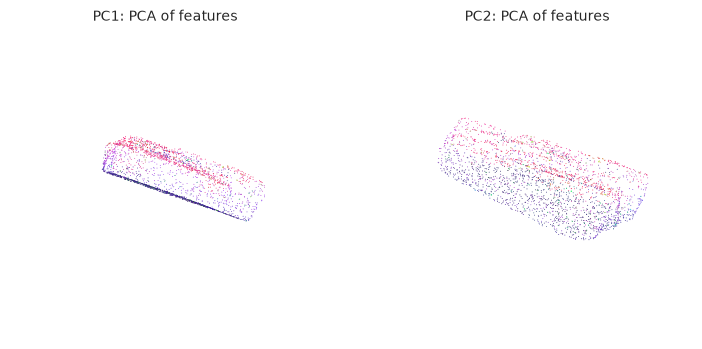

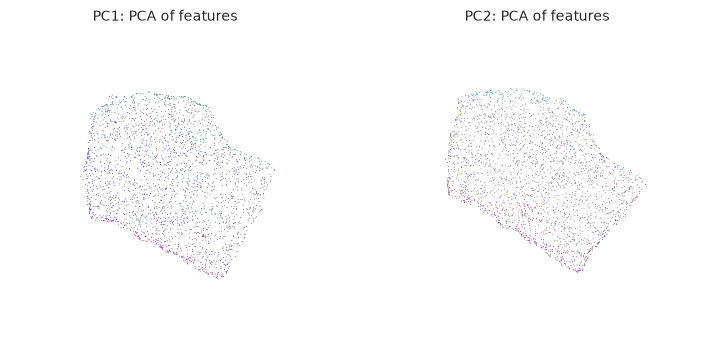

In [144]:
for i in range(ptv3_features_pc1.shape[0]):
    pca_pc1 = pca_color(ptv3_features_pc1[i])
    pca_pc2 = pca_color(ptv3_features_pc2[i])
    show_clouds(
        [{"pos": pc_info1[0][i].cpu().numpy(), "color": pca_pc1.cpu().numpy()}, {"pos": pc_info2[0][i].cpu().numpy(), "color": pca_pc2.cpu().numpy()}],
        ["PC1: PCA of features", "PC2: PCA of features"],
        point_size=0.4,
    )

In [147]:
import gc

PTV3


/home/enego/Documents/masters/RayRepresentationTesting/.venv/lib/python3.12/site-packages/torch_pointcloud/models/_registry.py:462: UserWarning: Ignoring checkpoint keys from 'hf://torch-pointcloud/ptv3-base.s3dis-area5.pointcept/resolve/main/model.safetensors' absent from the model: head.bias, head.weight.
  load_state_dict(model, read_state_dict(local_path), source=weights["url"])


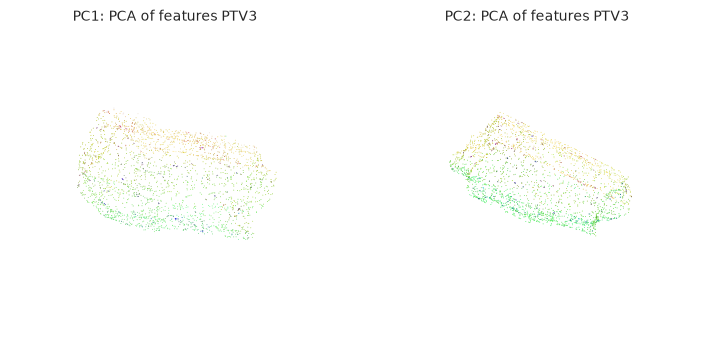

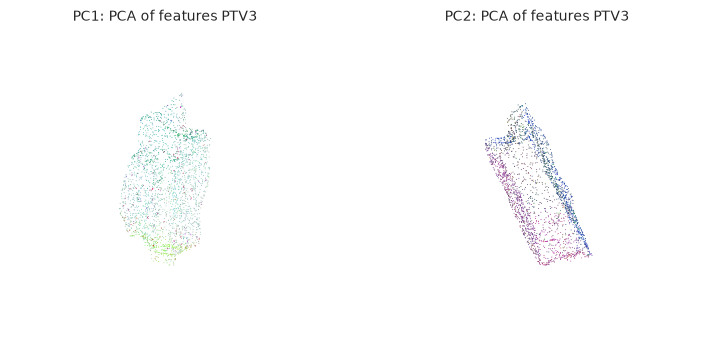

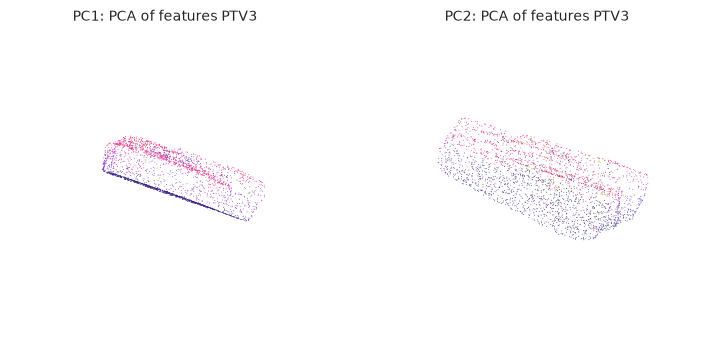

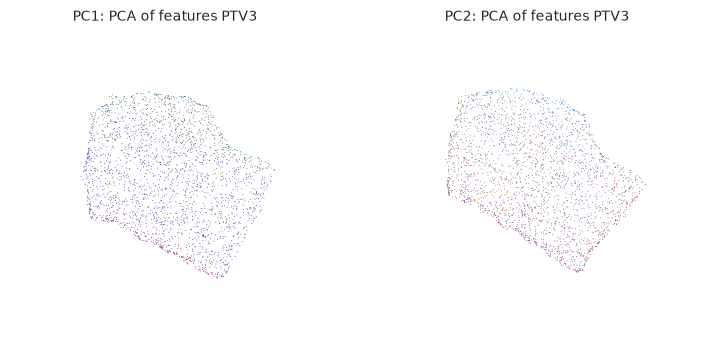

Sonata


/home/enego/Documents/masters/RayRepresentationTesting/.venv/lib/python3.12/site-packages/torch_pointcloud/models/_registry.py:462: UserWarning: Ignoring checkpoint keys from 'hf://torch-pointcloud/sonata-lp.scannet20.fair/resolve/main/model.safetensors' absent from the model: head.bias, head.weight.
  load_state_dict(model, read_state_dict(local_path), source=weights["url"])


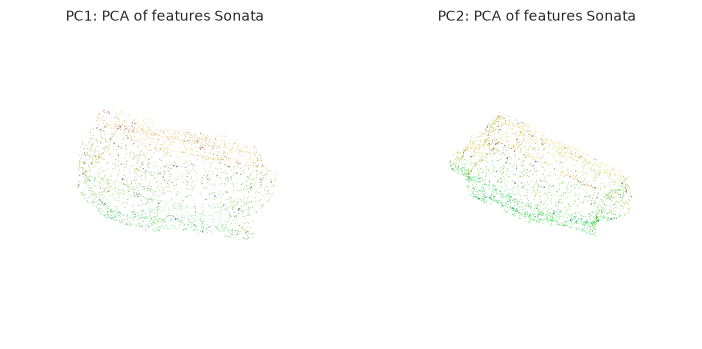

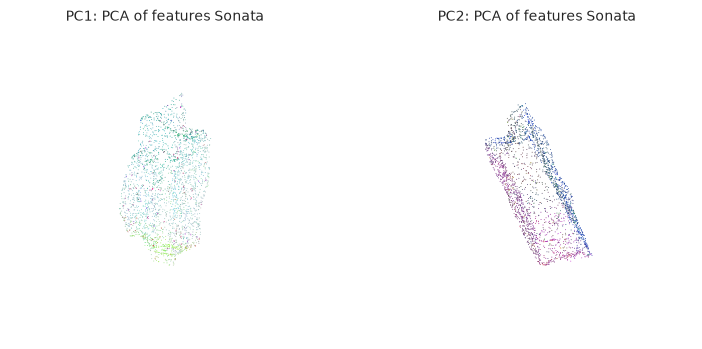

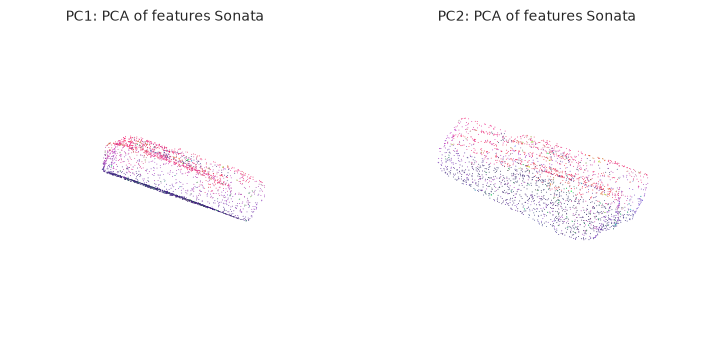

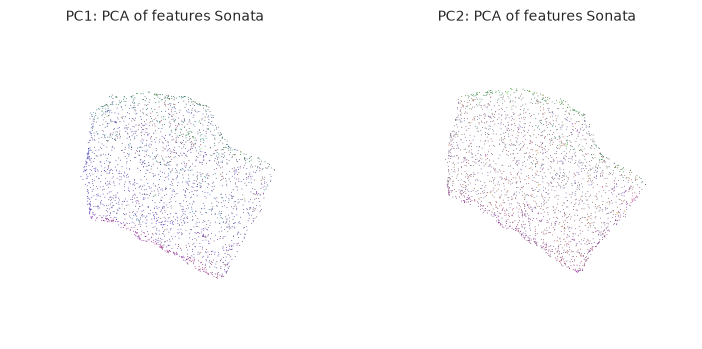

EM3FEncoder
❌ No-Overlap Loss is DISABLED.


/home/enego/Documents/masters/RayRepresentationTesting/EvaluationUtils.py:401: Hydra14MigrationWarning: 
The version_base parameter is not specified.
Hydra will assume defaults for version 1.1.
Hydra 1.4 will remove this compatibility behavior.
Before upgrading to Hydra 1.4, set version_base="1.3" and test your application.
See https://hydra.cc/docs/upgrades/1.3_to_1.4/prepare_for_1_4/ for preparation instructions.
  with initialize(config_path="em3rf/configs"):


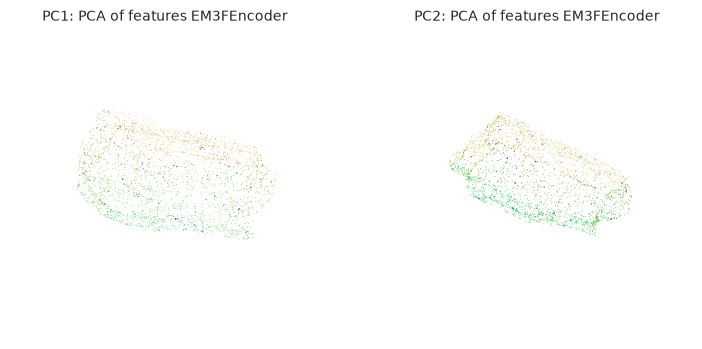

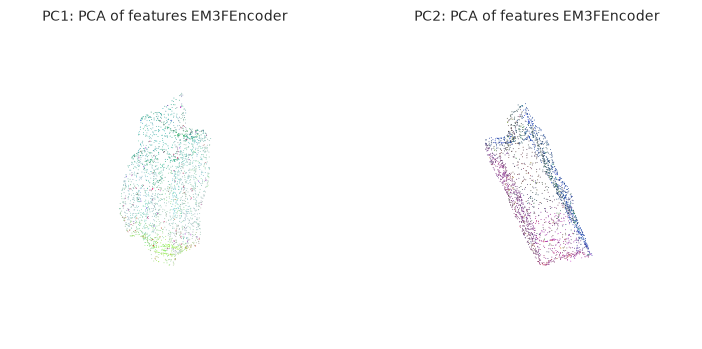

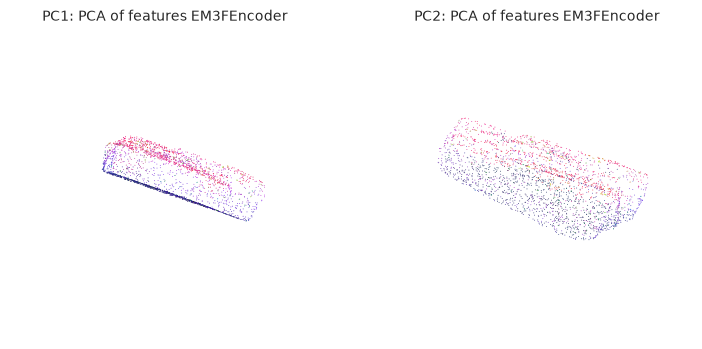

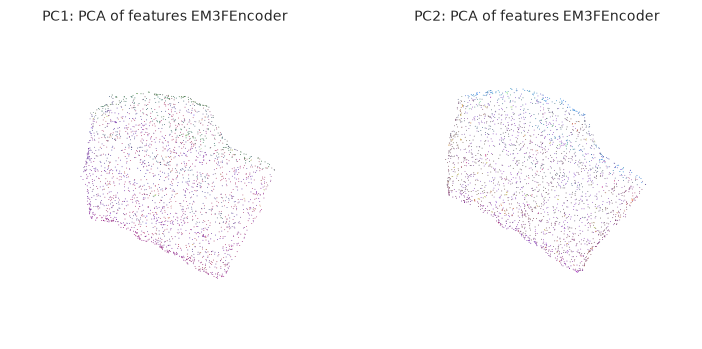

PointNet2


/home/enego/Documents/masters/RayRepresentationTesting/.venv/lib/python3.12/site-packages/torch_pointcloud/models/_registry.py:462: UserWarning: Ignoring checkpoint keys from 'hf://torch-pointcloud/pointnet2.s3dis-area5.openpoints/resolve/main/model.safetensors' absent from the model: head.lins.0.bias, head.lins.0.weight, head.lins.1.bias, head.lins.1.weight, head.norms.0.module.bias, head.norms.0.module.num_batches_tracked, head.norms.0.module.running_mean, head.norms.0.module.running_var, head.norms.0.module.weight.
  load_state_dict(model, read_state_dict(local_path), source=weights["url"])


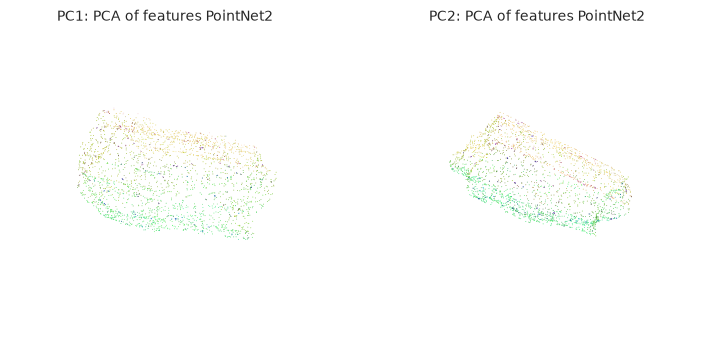

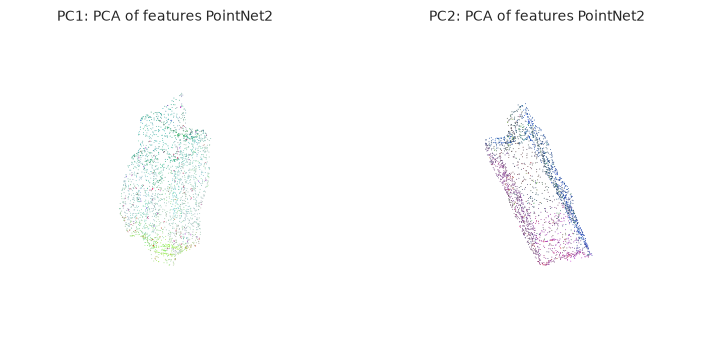

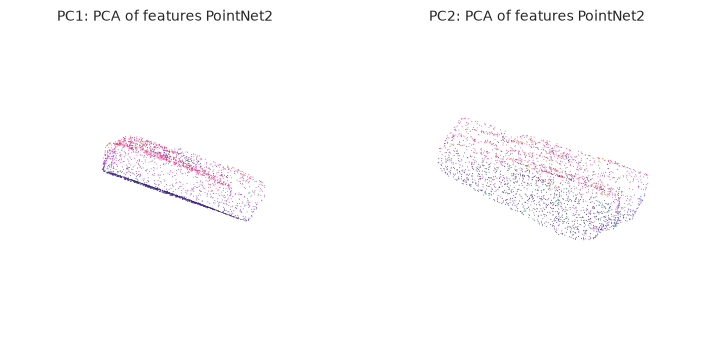

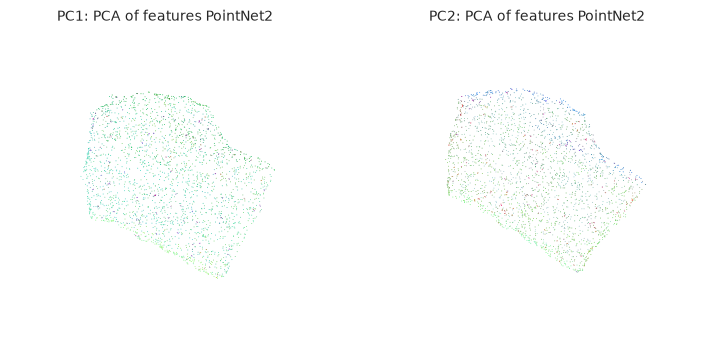

In [150]:
models = ["PTV3", "Sonata", "EM3FEncoder", "PointNet2"]

for model_name in models:
    print(model_name)
    model = encoders[model_name]().to(device)

    features_pc1 = model(pc_info1)
    features_pc2 = model(pc_info2)

    for i in range(ptv3_features_pc1.shape[0]):
        pca_pc1 = pca_color(ptv3_features_pc1[i])
        pca_pc2 = pca_color(ptv3_features_pc2[i])
        show_clouds(
            [{"pos": pc_info1[0][i].cpu().numpy(), "color": pca_pc1.cpu().numpy()}, {"pos": pc_info2[0][i].cpu().numpy(), "color": pca_pc2.cpu().numpy()}],
            [f"PC1: PCA of features {model_name}", f"PC2: PCA of features {model_name}"],
            point_size=0.4,
        )
    del model
    torch.cuda.memory.empty_cache()
    gc.collect()

In [ ]:
show_clouds(
    [{"pos": sample["pos"], "color": sample["color"] / 255}, {"pos": data["origin_pos"], "color": rgb[data["inverse"]]}],
    ["input: color from the scanner", f"PCA of {features.shape[1]:,} features per point"],
    point_size=0.4,
)